In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-05/PRJNA720269/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,BioSampleModel,Bytes,Center.Name,Collection_Date,⋯,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,smoke_status,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<int>,<chr>
1,SRR14161216,AMPLICON,495,17201008,PRJNA720269,SAMN18644554,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",5733371,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,PCR,METAGENOMIC,human metagenome,ILLUMINA,2021-05-12T00:00:00Z,2021-04-07T05:19:00Z,1,mishan1184,0,SRP313756
2,SRR14161222,AMPLICON,497,38045947,PRJNA720269,SAMN18644548,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",12769123,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,PCR,METAGENOMIC,human metagenome,ILLUMINA,2021-05-12T00:00:00Z,2021-04-07T05:19:00Z,1,mishan404,0,SRP313756
3,SRR14161223,AMPLICON,497,33284202,PRJNA720269,SAMN18644547,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",10949163,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,PCR,METAGENOMIC,human metagenome,ILLUMINA,2021-05-12T00:00:00Z,2021-04-07T05:19:00Z,1,YQ1702,0,SRP313756
4,SRR14161249,AMPLICON,497,23451176,PRJNA720269,SAMN18644589,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",7770244,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,PCR,METAGENOMIC,human metagenome,ILLUMINA,2021-05-12T00:00:00Z,2021-04-07T05:19:00Z,1,mishan179,0,SRP313756
5,SRR14161258,AMPLICON,497,22532828,PRJNA720269,SAMN18644581,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",7494177,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,PCR,METAGENOMIC,human metagenome,ILLUMINA,2021-05-12T00:00:00Z,2021-04-07T05:19:00Z,1,YQ1663,0,SRP313756
6,SRR14161259,AMPLICON,496,12178787,PRJNA720269,SAMN18644580,"MIMARKS.survey,MIGS/MIMS/MIMARKS.human-oral",4081715,SUN YAT-SEN UNIVERSITY CANCER CENTER,not collected,⋯,PCR,METAGENOMIC,human metagenome,ILLUMINA,2021-05-12T00:00:00Z,2021-04-07T05:19:00Z,1,mishan1298,0,SRP313756


[1] "Run"                            "Assay.Type"                    
 [3] "AvgSpotLen"                     "Bases"                         
 [5] "BioProject"                     "BioSample"                     
 [7] "BioSampleModel"                 "Bytes"                         
 [9] "Center.Name"                    "Collection_Date"               
[11] "Consent"                        "DATASTORE.filetype"            
[13] "DATASTORE.provider"             "DATASTORE.region"              
[15] "education_group"                "env_broad_scale"               
[17] "env_local_scale"                "env_medium"                    
[19] "Experiment"                     "geo_loc_name_country"          
[21] "geo_loc_name_country_continent" "geo_loc_name"                  
[23] "Host_Age"                       "host_body_product"             
[25] "host_phenotype"                 "HOST"                          
[27] "host_sex"                       "Instrument"                    
[29] "lat_lon"                        "Library.Name"                  
[31] "LibraryLayout"                  "LibrarySelection"              
[33] "LibrarySource"                  "Organism"                      
[35] "Platform"                       "ReleaseDate"                   
[37] "create_date"                    "version"                       
[39] "Sample.Name"                    "smoke_status"                  
[41] "SRA.Study"

In [3]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$'Sample.Name',
    Age = initial_meta$Host_Age,
    BMI = NA,
    Sex = initial_meta$host_sex,
    Region = 'V4',
    Platform = initial_meta$Platform,
    Country = initial_meta$geo_loc_name_country,
    Site = initial_meta$host_body_product,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = 'F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT',
    title = "Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population",
    Disease_study = "NO",
    Status = NA,
    matched_samples = 'NO')

In [4]:
print(length(unique(uniform_meta$Run)))
print(length(unique(uniform_meta$sample_name)))

[1] 166
[1] 166


In [5]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<int>,<lgl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>,<chr>
1,PRJNA720269,SRR14161216,mishan1184,49,NA,male,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO
2,PRJNA720269,SRR14161222,mishan404,34,NA,female,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO
3,PRJNA720269,SRR14161223,YQ1702,32,NA,male,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO
4,PRJNA720269,SRR14161249,mishan179,31,NA,female,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO
5,PRJNA720269,SRR14161258,YQ1663,31,NA,male,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO
6,PRJNA720269,SRR14161259,mishan1298,30,NA,male,V4,ILLUMINA,China,saliva,2021-05-12T00:00:00Z,F: GTGCCAGCMGCCGCGGTAA; R: GGACTACHVGGGGGTWTCTAAT,Association Between Oral Microbiota and Cigarette Smoking in the Chinese Population,NO,NA,NO


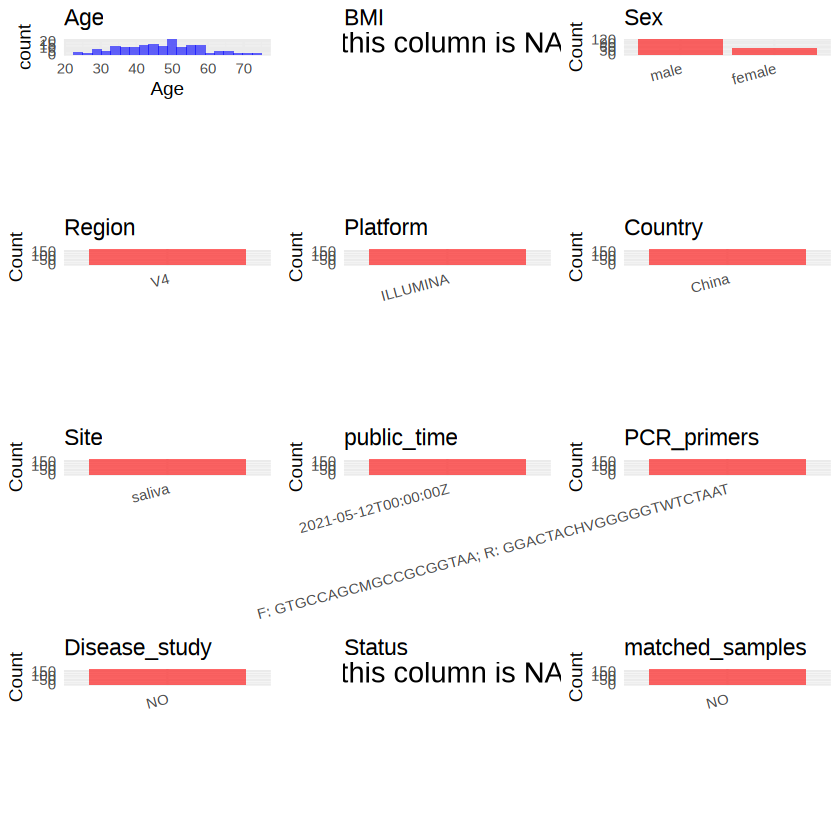

In [6]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [7]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-05/PRJNA720269/metadata.csv", quote = T)